# NORDCART REVENUE DECLINE ANALYSIS

### Author: Gordon Moenga

# 1. Introduction
NordCart is a growing direct-to-consumer e-commerce company that has expanded from a single-category retailer into an 8-category business serving customers across Europe and North America. Despite being profitable and having a strong base of repeat customers, the company experienced an 18% decline in revenue in Q3, while order volume reportedly increased. This created a business concern for leadership because higher order volume would normally be expected to generate higher revenue. The analysis therefore focuses on understanding what changed in Q3, including whether customers spent less per order, discounts increased, refunds or cancellations affected revenue, or specific products, channels, or customer segments contributed to the decline.

Using the Products, Sessions, and Orders datasets, the analysis examines NordCart's sales performance, customer activity, product performance, acquisition channels, and order behaviour to identify the main drivers of the revenue decline. The findings are intended to give leadership a clear, data-backed understanding of what happened in Q3 and support a specific recommendation for the company's Q4 promotional strategy before the budget is finalised.


# 2. Business Understanding
#### Problem Statement

NordCart's CFO reported an 18% decline in revenue in Q3, while the operations team reported that order volume increased during the same period. This contradiction raised concerns about the company's sales performance and the underlying drivers of revenue. This project addresses the 18% Q3 revenue decline despite increased order volume by identifying its key financial and operational drivers and determine where corrective action is rrequired.

#### Project Objective

To identify why revenue declined despite increased order volume, determine which channels, categories, and customer segments contributed to the decline, quantify the impact of AOV erosion, refunds, and lost customers, and provide the CMO with a specific promotional strategy recommendation for Q4.

#### Success Metric

Success will be measured by delivering a clear, data-backed explanation of the Q3 revenue decline and its financial drivers. The findings should provide the CFO and CMO with actionable insights to support Q4 budget allocation and promotional strategy decisions.

# 3. Data Understanding

The analysis uses three separate datasets: Products, Sessions, and Orders that provide different views of NordCart's business performance during 2024. They were used to examine the relationship between the products NordCart sells, how customers interact with the website, and the orders and revenue generated.

| Dataset      | Key Variables                                                                                                                                                               |
| ------------ | --------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Products** | `product_id`, `category`, `cost_price`, `list_price`, `stock_level`, `is_active`, `supplier_country`, `launch_date`                                                         |
| **Sessions** | `session_id`, `customer_id`, `session_date`, `channel`, `country`, `pages_viewed`, `session_duration_sec`, `bounced`, `converted`, `utm_campaign`                           |
| **Orders**   | `order_id`, `customer_id`, `order_date`, `product_id`, `category`, `quantity`, `unit_price`, `discount_amount`, `revenue`, `status`, `channel`, `country`, `is_first_order` |

#### Key Observation

The datasets contain missing values in customer IDs, revenue, discounts, channels, and campaign information, as well as inconsistent customer-order classifications and unusual pricing and revenue values. These issues could affect the accuracy of AOV, refund, customer, channel, and promotional performance analysis, making data cleaning and validation necessary before drawing conclusions.

### Import the Required Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import sqlite3
import matplotlib.pyplot as plt

### Load the datasets

In [2]:
products = pd.read_csv("NordCart_products.csv")
sessions = pd.read_csv("NordCart_sessions.csv")
orders = pd.read_csv("NordCart__orders.csv")

### Exploring the Datasets

In [3]:
# load the dataset information
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   product_id        80 non-null     object 
 1   product_name      80 non-null     object 
 2   category          80 non-null     object 
 3   cost_price        80 non-null     float64
 4   list_price        80 non-null     float64
 5   stock_level       80 non-null     int64  
 6   is_active         80 non-null     object 
 7   supplier_country  80 non-null     object 
 8   launch_date       80 non-null     object 
 9   weight_kg         72 non-null     float64
dtypes: float64(3), int64(1), object(6)
memory usage: 6.4+ KB


In [4]:
# identify the 8 categories introduced by the company
products.category.value_counts()

category
Apparel          17
Books            13
Beauty           12
Toys             10
Electronics       9
Home & Garden     8
Food              6
Sports            5
Name: count, dtype: int64

In [5]:
# investigate is_active column
products.is_active.value_counts(dropna=False)

is_active
1    32
Y    31
N     9
0     8
Name: count, dtype: int64

In [6]:
# identify duplicates
products.product_id.duplicated().sum()

np.int64(0)

In [7]:
# identify whether missing values exist
products.isnull().sum()

product_id          0
product_name        0
category            0
cost_price          0
list_price          0
stock_level         0
is_active           0
supplier_country    0
launch_date         0
weight_kg           8
dtype: int64

In [8]:
# investigate all numerical columns
products.describe()

,cost_price,list_price,stock_level,weight_kg
count,80.000000,80.000000,80.000000,72.000000
mean,34.627625,79.547250,153.312500,6.080694
std,16.334265,43.610473,87.966132,3.420834
min,8.710000,22.820000,0.000000,0.350000
25%,19.430000,42.127500,73.000000,2.635000
50%,34.590000,73.530000,173.500000,6.440000
75%,49.840000,107.577500,228.750000,8.917500
max,59.950000,187.300000,300.000000,11.950000


In [9]:
# identify launch dates range
products.launch_date.min(), products.launch_date.max()

('2022-01-14', '2024-06-01')

In [10]:
sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   session_id            22000 non-null  object
 1   customer_id           18055 non-null  object
 2   session_date          22000 non-null  object
 3   channel               22000 non-null  object
 4   device                22000 non-null  object
 5   country               22000 non-null  object
 6   pages_viewed          22000 non-null  int64 
 7   session_duration_sec  22000 non-null  int64 
 8   bounced               20890 non-null  object
 9   converted             22000 non-null  bool  
 10  utm_source            19345 non-null  object
 11  utm_campaign          15587 non-null  object
dtypes: bool(1), int64(2), object(9)
memory usage: 1.9+ MB


In [11]:
# check for duplicates in the dataset
sessions.session_id.duplicated().sum()

np.int64(0)

In [12]:
# identify whether null values exist
sessions.isnull().sum()

session_id                 0
customer_id             3945
session_date               0
channel                    0
device                     0
country                    0
pages_viewed               0
session_duration_sec       0
bounced                 1110
converted                  0
utm_source              2655
utm_campaign            6413
dtype: int64

In [13]:
# identify the acquisition channels
sessions.channel.value_counts()

channel
referral       3804
organic        3695
paid_search    3688
direct         3635
paid_social    3620
email          3558
Name: count, dtype: int64

In [14]:
# inspeect countries where products are shipped to
sessions.country.value_counts()

country
UK    4778
US    3175
NL    3159
FR    3121
DE    3048
DK    1596
SE    1569
NO    1554
Name: count, dtype: int64

In [15]:
# inspect numerical behaviour of the dataset
sessions.describe()

,pages_viewed,session_duration_sec
count,22000.000000,22000.000000
mean,5.654545,334.469909
std,5.726086,387.301121
min,1.000000,3.000000
25%,1.000000,17.000000
50%,2.000000,96.000000
75%,10.000000,650.250000
max,18.000000,1200.000000


In [16]:
# identify the total number of bounced sessions
sessions.bounced.value_counts(dropna=False)

bounced
False    10804
True     10086
NaN       1110
Name: count, dtype: int64

In [17]:
# identify the total number of converted sessions
sessions.converted.value_counts()

converted
False    21525
True       475
Name: count, dtype: int64

In [18]:
# inspect the utm sources
sessions.utm_source.value_counts(dropna=False)

utm_source
none          8396
instagram     2748
google        2746
newsletter    2729
facebook      2726
NaN           2655
Name: count, dtype: int64

In [19]:
# inspect utm campaigns
sessions.utm_campaign.value_counts(dropna=False)

utm_campaign
NaN            6413
none           3188
summer_sale    3156
brand          3125
promo_Q3       3098
retargeting    3020
Name: count, dtype: int64

In [20]:
# date range for the orders
sessions.session_date.min(), sessions.session_date.max()

('2024-01-01', '2024-09-30')

In [21]:
# display summary of each column in the dataset
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         8000 non-null   object 
 1   customer_id      7838 non-null   object 
 2   order_date       8000 non-null   object 
 3   product_id       7924 non-null   object 
 4   category         7769 non-null   object 
 5   quantity         8000 non-null   int64  
 6   unit_price       7863 non-null   float64
 7   discount_amount  1834 non-null   float64
 8   revenue          7876 non-null   float64
 9   status           8000 non-null   object 
 10  channel          7512 non-null   object 
 11  country          7684 non-null   object 
 12  device           8000 non-null   object 
 13  payment_method   6419 non-null   object 
 14  is_first_order   8000 non-null   object 
dtypes: float64(3), int64(1), object(11)
memory usage: 937.6+ KB


In [22]:
# check for order duplicates
orders["order_id"].duplicated().sum()

np.int64(0)

In [23]:
# check for null values in the dataset
orders.isnull().sum()

order_id              0
customer_id         162
order_date            0
product_id           76
category            231
quantity              0
unit_price          137
discount_amount    6166
revenue             124
status                0
channel             488
country             316
device                0
payment_method     1581
is_first_order        0
dtype: int64

In [24]:
# check for the type of status that exists
orders.status.value_counts()

status
completed    4815
refunded     1856
cancelled    1329
Name: count, dtype: int64

In [25]:
# check for new and returning customers
orders["is_first_order"].value_counts()

is_first_order
N      3147
Y      1629
1       835
0       816
yes     794
no      779
Name: count, dtype: int64

In [26]:
# identify the different categories in the dataset
orders.category.value_counts()

category
Home & Garden    999
Food             998
Beauty           989
Toys             989
Sports           967
Apparel          960
Electronics      956
Books            911
Name: count, dtype: int64

In [27]:
# identify channels used
orders.channel.value_counts()

channel
email          1301
paid_social    1296
organic        1267
paid_search    1245
direct         1217
referral       1186
Name: count, dtype: int64

In [28]:
# list countries and total orders for each
orders.country.value_counts()

country
UK    1664
DE    1090
NL    1089
US    1080
FR    1074
DK     585
NO     556
SE     546
Name: count, dtype: int64

In [29]:
# numerical summary
orders.describe()

,quantity,unit_price,discount_amount,revenue
count,8000.000000,7863.000000,1834.000000,7876.000000
mean,2.328250,60.317861,8.785038,138.863024
std,1.050067,24.819737,6.155787,91.552625
min,1.000000,-107.300000,0.010000,-428.920000
25%,1.000000,48.050000,3.820000,69.777500
50%,2.000000,61.900000,7.880000,124.810000
75%,3.000000,75.170000,12.615000,194.962500
max,4.000000,133.530000,35.420000,491.920000


In [30]:
# date range for the orders made
orders["order_date"].min(), orders["order_date"].max()

('2024-01-01', '2024-09-30')

# 4. Data Cleaning and Preparation

To transform the raw datasets into a reliable format for analysis, a structured data preparation workflow was implemented. These steps focused on improving consistency, preserving relevant information, and ensuring that the datasets were suitable for subsequent EDA, SQL analysis, and visualisation.

#### Data Cleaning Process

The datasets were refined through a series of cleaning operations applied according to their relevance to the business objectives:

* Inconsistent categorical values were standardised, including `is_active` in the Products dataset and `is_first_order` in the Orders dataset.
* `launch_date`, `session_date`, and `order_date` were converted from object format to datetime to support time-based analysis.
* Missing values were investigated individually rather than removed indiscriminately. Non-critical missing values, such as the 8 missing `weight_kg` values, were retained and documented.
* Missing `customer_id`, `bounced`, `utm_source`, `utm_campaign`, `channel`, and `country` values were retained where they could not be reliably recovered, with their limitations documented for subsequent analysis.
* 227 missing order categories were recovered by matching `product_id` in the Orders dataset to the Products dataset.
* Missing `unit_price` and `revenue` values were not artificially imputed where reliable transaction values could not be established.
* 6,166 missing `discount_amount` values were retained rather than assuming that missing discounts represented zero discounts.
* Negative `unit_price` values and 94 negative revenue records were identified as data-quality issues and excluded from relevant AOV and revenue calculations while the original records were retained for traceability.
* Date ranges and duplicate `order_id` values were checked to ensure the datasets remained structurally consistent after cleaning.

#### Results

The datasets were successfully prepared for analysis while minimising unnecessary data loss. Relevant missing and invalid values were identified, recoverable information was restored where possible, and data-quality limitations were documented.

### 4.1 Products

In [31]:
# standardise the is_active column to 'Yes' and 'No' status
products['is_active'] = products['is_active'].replace({
    "1":"Yes",
    "Y":"Yes",
    "0":"No",
    "N":"No"
})

In [32]:
# verify the result
products['is_active'].value_counts()

is_active
Yes    63
No     17
Name: count, dtype: int64

In [33]:
# convert launch_date to datetime
products['launch_date'] = pd.to_datetime(products["launch_date"])

### 4.2 Sessions

In [34]:
# convert session_date dtype to datetime
sessions['session_date'] = pd.to_datetime(sessions['session_date'])

In [35]:
# identify number of sessions with missing customerid
sessions['customer_id'].isna().sum()

np.int64(3945)

In [36]:
# check whether the sessions were converted
sessions[sessions['customer_id'].isna()]['converted'].value_counts()

converted
False    3876
True       69
Name: count, dtype: int64

In [37]:
sessions[sessions['bounced'].isna()]['converted'].value_counts()

converted
False    1089
True       21
Name: count, dtype: int64

In [38]:
# check whether missing values for utm_source do correspond to any particular campaign or channel pattern.
sessions[sessions['utm_source'].isna()]['channel'].value_counts()

channel
referral       462
organic        446
direct         444
paid_social    441
paid_search    434
email          428
Name: count, dtype: int64

In [39]:
# check whether missing values for utm_campaign do correspond to any particular campaign or channel pattern.
sessions[sessions['utm_campaign'].isna()]['channel'].value_counts()

channel
referral       1106
organic        1085
direct         1070
paid_search    1060
paid_social    1047
email          1045
Name: count, dtype: int64

### 4.3 Orders

In [40]:
# convert order_date dtype to datetime
orders['order_date'] = pd.to_datetime(orders['order_date'])

In [41]:
orders['is_first_order'].value_counts()

is_first_order
N      3147
Y      1629
1       835
0       816
yes     794
no      779
Name: count, dtype: int64

In [42]:
# standardise is_first_order column to have only 'Yes' and 'No' values
orders['is_first_order'] = orders['is_first_order'].replace({
    "N":"No",
    "no":"No",
    "0":"No",
    "Y":"Yes",
    "yes":"Yes",
    "1":"Yes"
})

In [43]:
# verify the standardisation step
orders['is_first_order'].value_counts()

is_first_order
No     4742
Yes    3258
Name: count, dtype: int64

In [44]:
# checking whether missing customerid values have a status value
orders[orders['customer_id'].isna()]['status'].value_counts()

status
completed    83
refunded     44
cancelled    35
Name: count, dtype: int64

In [45]:
# checking whether missing productid values have a status value
orders[orders['product_id'].isna()]['status'].value_counts()

status
completed    40
refunded     27
cancelled     9
Name: count, dtype: int64

In [46]:
# investigate missing category orders have a valid productid
orders[orders['category'].isna()]['product_id'].notna().value_counts()

product_id
True     227
False      4
Name: count, dtype: int64

Since the Products dataset contains the product-to-category relationship, we can use product_id to recover the category for those 227 orders.

In [47]:
# create a mapping
product_category = products.set_index('product_id')['category']

In [48]:
# fill the missing categories
orders['category'] = orders['category'].fillna(
    orders['product_id'].map(product_category)
)

In [49]:
# verify if conversion was successful
orders[orders['category'].isna()]['product_id'].notna().value_counts()

product_id
False    4
Name: count, dtype: int64

In [50]:
# check how many orders that have missing unit price have productid
orders[orders['unit_price'].isna()]['product_id'].notna().value_counts()

product_id
True     135
False      2
Name: count, dtype: int64

In [51]:
# check how many orders that have missing revenue have missing information needed to reconstruct revenue values
orders[orders['revenue'].isna()]['discount_amount'].isna().value_counts()

discount_amount
True     97
False    27
Name: count, dtype: int64

In [52]:
# check whether discount_amount is recorded as 0 where there's none
orders['discount_amount'].value_counts(dropna=False).head(10)

discount_amount
NaN     6166
3.26       6
4.35       5
5.96       5
9.88       5
2.42       5
0.20       4
6.92       4
1.26       4
7.09       4
Name: count, dtype: int64

In [53]:
# investigate negative unit price
orders[orders['unit_price'] < 0][['revenue', 'quantity', 'unit_price', 'order_id', 'status']]

,revenue,quantity,unit_price,order_id,status
33,18.64,1,-23.77,ORD-00034,refunded
72,131.70,3,-43.90,ORD-00073,completed
77,186.90,3,-62.30,ORD-00078,completed
267,177.88,2,-88.94,ORD-00268,refunded
304,44.56,1,-44.56,ORD-00305,completed
...,...,...,...,...,...
7690,-294.48,4,-73.62,ORD-07691,refunded
7877,244.47,3,-81.49,ORD-07878,completed
7932,149.56,4,-45.69,ORD-07933,completed
7938,126.03,3,-42.64,ORD-07939,refunded


In [54]:
# investigate negative revenue
orders[orders['revenue'] < 0][['revenue', 'quantity', 'unit_price', 'order_id', 'status']]

,revenue,quantity,unit_price,order_id,status
0,-65.21,1,67.28,ORD-00001,cancelled
46,-123.39,3,57.88,ORD-00047,completed
53,-202.48,4,60.33,ORD-00054,completed
131,-162.90,2,81.45,ORD-00132,completed
239,-73.90,1,73.90,ORD-00240,completed
...,...,...,...,...,...
7459,-52.56,1,52.56,ORD-07460,completed
7690,-294.48,4,-73.62,ORD-07691,refunded
7741,-248.49,3,82.83,ORD-07742,completed
7839,-51.50,1,51.50,ORD-07840,completed


In [55]:
orders['order_date'].min(), orders['order_date'].max()

(Timestamp('2024-01-01 00:00:00'), Timestamp('2024-09-30 00:00:00'))

# 5. Exploratory Data Analysis

## 5.1 Q2 vs Q3 Performance

#### Q2 vs Q3

In [56]:
# number of orders in each quarter
orders["quarter"] = orders["order_date"].dt.quarter
orders["quarter"].value_counts().sort_index()

quarter
1    2675
2    2589
3    2736
Name: count, dtype: int64

In [57]:
# load the cleaned orders dataset into sqlite
connect = sqlite3.connect(":memory:")

orders.to_sql(
    "orders",
    connect,
    index=False
)

8000

In [58]:
# create a table showing total revenue for each quarter
query = """
SELECT 
    CASE
        WHEN strftime('%m', order_date) BETWEEN '04' AND '06' THEN 'Q2'
        WHEN strftime('%m', order_date) BETWEEN '07' AND '09' THEN 'Q3'
    END AS quarter,
    
    COUNT(DISTINCT order_id) AS order_count,
    
    SUM(revenue) AS total_revenue

FROM orders
WHERE strftime('%m', order_date) BETWEEN '04' AND '09'
GROUP BY quarter
"""

revenue = pd.read_sql_query(query, connect)
revenue

,quarter,order_count,total_revenue
0,Q2,2589,415576.07
1,Q3,2736,248507.17


In [59]:
revenue_diff = (
    revenue.loc[revenue["quarter"] == "Q3", "total_revenue"].iloc[0]
    - revenue.loc[revenue["quarter"] == "Q2", "total_revenue"].iloc[0]
)

revenue_diffrevenue_diff = (
    revenue.loc[revenue["quarter"] == "Q3", "total_revenue"].iloc[0]
    - revenue.loc[revenue["quarter"] == "Q2", "total_revenue"].iloc[0]
)

revenue_diff

np.float64(-167068.9)

#### AOV

In [60]:
aov_query = """
SELECT 
    CASE
        WHEN strftime('%m', order_date) BETWEEN '04' AND '06' THEN 'Q2'
        WHEN strftime('%m', order_date) BETWEEN '07' AND '09' THEN 'Q3'
    END AS quarter,
    
    COUNT(*) AS order_count,
    
    SUM(
        CASE
            WHEN status = 'completed' AND revenue >= 0 THEN revenue
            ELSE 0
        END
    ) AS revenue,
    
    COUNT(
        DISTINCT CASE
            WHEN status = 'completed' THEN order_id
        END
    ) AS completed_orders
    
FROM orders
WHERE strftime('%m', order_date) BETWEEN '04' AND '09'
GROUP BY quarter
ORDER BY quarter;
"""

aov_data = pd.read_sql_query(aov_query, connect)
aov_data

,quarter,order_count,revenue,completed_orders
0,Q2,2589,275149.96,1703
1,Q3,2736,124955.57,1374


In [61]:
# use the formula [AOV = Revenue ÷ Completed Orders]
aov_data['AOV'] = aov_data['revenue'] / aov_data['completed_orders']
aov_data

,quarter,order_count,revenue,completed_orders,AOV
0,Q2,2589,275149.96,1703,161.567798
1,Q3,2736,124955.57,1374,90.942918


#### Discount Rate

In [62]:
discount_query = """
SELECT 
    CASE
        WHEN strftime('%m', order_date) BETWEEN '04' AND '06' THEN 'Q2'
        WHEN strftime('%m', order_date) BETWEEN '07' AND '09' THEN 'Q3'
    END AS quarter,
    
    SUM(discount_amount) AS total_discount,
    
    COUNT(
        CASE
            WHEN discount_amount IS NOT NULL THEN 1
        END
    ) AS orders_discounted

FROM orders
WHERE strftime('%m', order_date) BETWEEN '04' AND '09'
GROUP BY quarter
ORDER BY quarter;
"""

discount_data = pd.read_sql_query(discount_query, connect)
discount_data

,quarter,total_discount,orders_discounted
0,Q2,4124.29,386
1,Q3,8065.40,1046


In [63]:
# calculate average discount
discount_data['avg_discount'] = discount_data['total_discount'] / discount_data['orders_discounted']
discount_data

,quarter,total_discount,orders_discounted,avg_discount
0,Q2,4124.29,386,10.684689
1,Q3,8065.40,1046,7.710707


#### Refund Rate

In [64]:
refund_query = """
SELECT 
    CASE
        WHEN strftime('%m', order_date) BETWEEN '04' AND '06' THEN 'Q2'
        WHEN strftime('%m', order_date) BETWEEN '07' AND '09' THEN 'Q3'
    END AS quarter,
    
    COUNT(DISTINCT order_id) AS total_orders,
    
    COUNT(
        DISTINCT CASE
            WHEN status = 'refunded' THEN
            order_id
        END
    ) AS refunded_orders

FROM orders
WHERE strftime('%m', order_date) BETWEEN '04' AND '09'
GROUP BY quarter
ORDER BY quarter;
"""

refund_data = pd.read_sql_query(refund_query, connect)
refund_data

,quarter,total_orders,refunded_orders
0,Q2,2589,453
1,Q3,2736,921


In [65]:
# calculate the refund rate
refund_data['refund_rate'] = refund_data['refunded_orders'] / refund_data['total_orders']
refund_data

,quarter,total_orders,refunded_orders,refund_rate
0,Q2,2589,453,0.174971
1,Q3,2736,921,0.336623


#### Merging the results

In [66]:
# merge the tables to have quarter, order_count, total_revenue, aov, avg_discount and refund_rate on one table 

revenue_analysis = (
    revenue.merge(
        aov_data[['quarter', 'AOV']],
        on = 'quarter'
    )
    .merge(
        discount_data[['quarter', 'avg_discount']],
        on = 'quarter'
    )
    .merge(
        refund_data[['quarter', 'refund_rate']],
        on = 'quarter'
    )
)

revenue_analysis

,quarter,order_count,total_revenue,AOV,avg_discount,refund_rate
0,Q2,2589,415576.07,161.567798,10.684689,0.174971
1,Q3,2736,248507.17,90.942918,7.710707,0.336623


#### Comparison Table

In [67]:
# use q2 and q3 as row labels to create a comparison table
comparison = revenue_analysis.set_index('quarter')
comparison

,order_count,total_revenue,AOV,avg_discount,refund_rate
quarter,,,,,
Q2,2589,415576.07,161.567798,10.684689,0.174971
Q3,2736,248507.17,90.942918,7.710707,0.336623


In [68]:
# calculate the change
percentage_change = (
    (comparison.loc['Q3'] - comparison.loc['Q2'])
    / comparison.loc['Q2']
) * 100

percentage_change

order_count       5.677868
total_revenue   -40.201761
AOV             -43.712225
avg_discount    -27.834050
refund_rate      92.387737
dtype: float64

## 5.2 Revenue Decline by Channel

In [69]:
# create a revenue table for eacch quarter grouped by channel

Q2_query = """
SELECT
    channel,
    SUM(revenue) AS Q2_revenue

FROM orders
WHERE strftime('%m', order_date) IN('04', '05', '06')
GROUP BY channel
ORDER BY Q2_revenue DESC;
"""

Q2_revenue = pd.read_sql_query(Q2_query, connect)
Q2_revenue

,channel,Q2_revenue
0,paid_social,71239.99
1,email,67958.81
2,paid_search,65449.15
3,direct,63956.20
4,organic,63340.13
5,referral,60595.26
6,None,23036.53


In [70]:
Q3_query = """
SELECT
    channel,
    SUM(revenue) AS Q3_revenue

FROM orders
WHERE strftime('%m', order_date) IN('07', '08', '09')
GROUP BY channel
ORDER BY Q3_revenue DESC;
"""

Q3_revenue = pd.read_sql_query(Q3_query, connect)
Q3_revenue

,channel,Q3_revenue
0,email,43640.58
1,paid_social,40517.25
2,organic,39744.27
3,direct,37478.08
4,paid_search,35761.90
5,referral,34981.48
6,None,16383.61


In [71]:
channel_revenue = (
    Q2_revenue.merge(
        Q3_revenue[['channel', 'Q3_revenue']]
    )
)
channel_revenue

,channel,Q2_revenue,Q3_revenue
0,paid_social,71239.99,40517.25
1,email,67958.81,43640.58
2,paid_search,65449.15,35761.90
3,direct,63956.20,37478.08
4,organic,63340.13,39744.27
5,referral,60595.26,34981.48
6,None,23036.53,16383.61


In [72]:
# calculate the revenue change for each channel
channel_revenue['revenue_change'] = (
    channel_revenue['Q3_revenue'] - 
    channel_revenue['Q2_revenue']
)

channel_revenue

,channel,Q2_revenue,Q3_revenue,revenue_change
0,paid_social,71239.99,40517.25,-30722.74
1,email,67958.81,43640.58,-24318.23
2,paid_search,65449.15,35761.90,-29687.25
3,direct,63956.20,37478.08,-26478.12
4,organic,63340.13,39744.27,-23595.86
5,referral,60595.26,34981.48,-25613.78
6,None,23036.53,16383.61,-6652.92


In [73]:
channel_revenue['revenue_change'].sum()

np.float64(-167068.90000000002)

In [74]:
# calculate the percentage change
channel_revenue['revenue_change_pct'] = (
    channel_revenue['revenue_change'] / 
    channel_revenue['Q2_revenue']
) * 100

channel_revenue

,channel,Q2_revenue,Q3_revenue,revenue_change,revenue_change_pct
0,paid_social,71239.99,40517.25,-30722.74,-43.125694
1,email,67958.81,43640.58,-24318.23,-35.783778
2,paid_search,65449.15,35761.90,-29687.25,-45.359260
3,direct,63956.20,37478.08,-26478.12,-41.400396
4,organic,63340.13,39744.27,-23595.86,-37.252623
5,referral,60595.26,34981.48,-25613.78,-42.270270
6,None,23036.53,16383.61,-6652.92,-28.879870


Visualisation

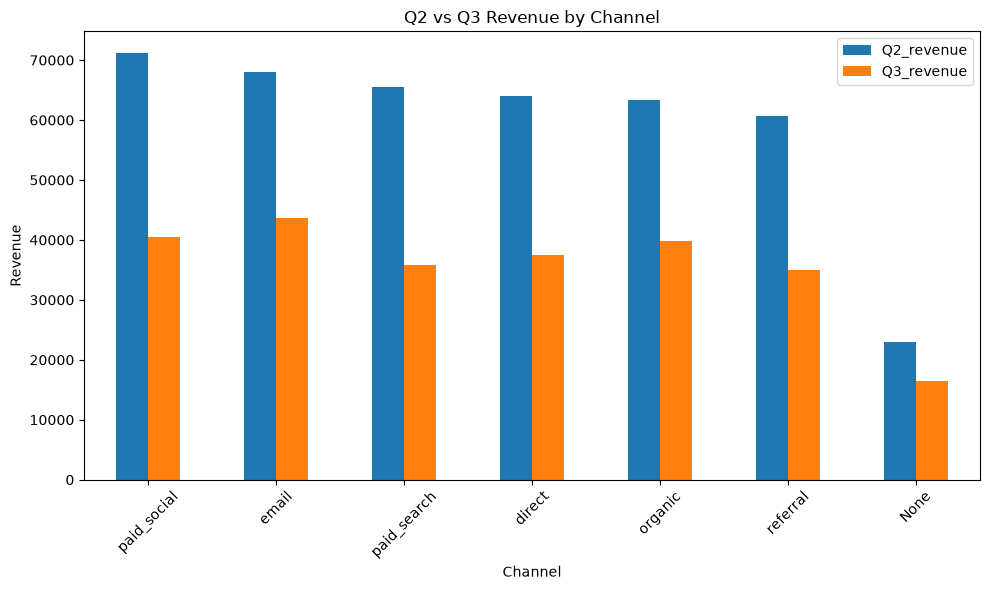

In [75]:
# visualise change in revenue in both q2 and q3
channel_revenue.plot(
    x='channel',
    y=['Q2_revenue', 'Q3_revenue'],
    kind='bar',
    figsize=(10,6)
)
plt.title("Q2 vs Q3 Revenue by Channel")
plt.xlabel("Channel")
plt.xticks(rotation=45)
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

Insight:

The revenue decline was broad-based across all major channels rather than isolated to paid social or email. Paid search experienced the largest percentage decline, while email experienced the smallest, indicating that the problem is unlikely to be attributable to a single acquisition channel.

## 5.3 Sessions & Conversion Analysis

Load sessions table

In [76]:
sessions.to_sql(
    'Sessions',
    connect,
    index=False
)

22000

Compare sessions and conversions

In [77]:
# strftime('%Y-%m', session_date) explicitly extracts the year and month from the datetime value

sessions_query = """
SELECT 
    CASE
        WHEN strftime('%Y-%m', session_date) IN ('2024-04', '2024-05', '2024-06')
            THEN 'Q2'
        WHEN strftime('%Y-%m', session_date) IN ('2024-07', '2024-08', '2024-09')
            THEN 'Q3'
    END AS quarter,
    
    COUNT(*) AS total_sessions,
    
    SUM(
        CASE
            WHEN converted = 1 THEN 1
            ELSE 0
        END
    ) AS converted_sessions

FROM sessions
WHERE strftime('%Y-%m', session_date) BETWEEN '2024-04-01' AND '2024-09-30'
GROUP BY quarter
ORDER BY quarter;
"""

sessions_data = pd.read_sql_query(sessions_query, connect)
sessions_data

,quarter,total_sessions,converted_sessions
0,Q2,4875,135
1,Q3,7383,77


Conversion rate

In [78]:
sessions_data['conversion_rate'] = (
    (sessions_data['converted_sessions'] /
     sessions_data['total_sessions']) * 100
)
sessions_data

,quarter,total_sessions,converted_sessions,conversion_rate
0,Q2,4875,135,2.769231
1,Q3,7383,77,1.042936


## 5.4 Discount Distribution

In [79]:
# create a table where each order's discount is added into a category
discount_distribution_query = """
SELECT
    CASE
        WHEN discount_amount IS NULL THEN 'Missing'
        WHEN discount_amount = 0 THEN 'No discount'
        WHEN (discount_amount / (unit_price * quantity)) * 100 <= 10 THEN '1-10%'
        WHEN (discount_amount / (unit_price * quantity)) * 100 <= 20 THEN '11-20%'
        WHEN (discount_amount / (unit_price * quantity)) * 100 <= 30 THEN '21-30%'
        ELSE '+30%'
    END AS discount_category,
    COUNT(*) AS order_count

FROM orders
GROUP BY discount_category
ORDER BY 
    CASE discount_category
        WHEN 'No discount' THEN 1
        WHEN '1-10%' THEN 2
        WHEN '11-20%' THEN 3
        WHEN '21-30%' THEN 4
        WHEN '+30%' THEN 5
        WHEN 'Missing' THEN 6
    END;
"""

discount_distribution_data = pd.read_sql_query(discount_distribution_query, connect)
discount_distribution_data

,discount_category,order_count
0,1-10%,1246
1,11-20%,385
2,21-30%,179
3,+30%,24
4,Missing,6166


Discount vs full-price AOV

In [80]:
discount_aov_query = """
SELECT
    CASE
        WHEN discount_amount > 0 THEN 'Discounted'
        WHEN discount_amount <= 0 THEN 'Full-price'
    END AS order_type,
    COUNT(*) AS order_count,
    SUM(revenue) AS total_revenue,
    AVG(revenue) AS AOV

FROM orders
WHERE discount_amount IS NOT NULL
GROUP BY order_type
ORDER BY order_type;
"""

discount_aov_data = pd.read_sql_query(discount_aov_query, connect)
discount_aov_data

,order_type,order_count,total_revenue,AOV
0,Discounted,1834,191935.11,106.217548


Insight:

All orders with recorded discount information had a positive discount. Of the 1,834 orders with discount data, only 24 received discounts above 30%, indicating that heavy discounting was uncommon. However, 6,166 orders have missing discount values, preventing a reliable comparison of discounted versus full-price AOV.

## 5.5 New vs Returning Customers

In [81]:
customer_revenue_query = """
SELECT 
    CASE
        WHEN is_first_order = 'Yes' THEN 'New'
        WHEN is_first_order = 'No' THEN 'Returning'
    END AS customer_type,
    COUNT(*) AS order_count,
    SUM(revenue) AS total_revenue,
    CASE
        WHEN strftime('%Y-%m', order_date) IN ('2024-04', '2024-05', '2024-06')
            THEN 'Q2'
        WHEN strftime('%Y-%m', order_date) IN ('2024-07', '2024-08', '2024-09')
            THEN 'Q3'
    END AS quarter

FROM orders
WHERE strftime('%Y-%m', order_date) BETWEEN '2024-04' AND '2024-09'
GROUP BY customer_type, quarter
ORDER BY customer_type, quarter;
"""

customer_revenue = pd.read_sql_query(customer_revenue_query, connect)
customer_revenue

,customer_type,order_count,total_revenue,quarter
0,New,1073,171035.28,Q2
1,New,1117,101721.34,Q3
2,Returning,1516,244540.79,Q2
3,Returning,1619,146785.83,Q3


In [82]:
revenue_data = customer_revenue.pivot(
    index = 'customer_type',
    columns = 'quarter',
    values = 'total_revenue'
)
revenue_data

quarter,Q2,Q3
customer_type,,
New,171035.28,101721.34
Returning,244540.79,146785.83


In [83]:
# calculate revenue change and revenue change percentage
revenue_data['revenue_change'] = (
    revenue_data['Q3'] - revenue_data['Q2']
)

revenue_data['revenue_change_pct'] = (
    revenue_data['revenue_change'] / revenue_data['Q2']
) * 100

revenue_data

quarter,Q2,Q3,revenue_change,revenue_change_pct
customer_type,,,,
New,171035.28,101721.34,-69313.94,-40.526107
Returning,244540.79,146785.83,-97754.96,-39.974910


Insight:

Revenue declined at a similar rate among both new and returning customers, while order volumes increased. This indicates that the decline was broad-based rather than driven specifically by customer acquisition or retention. The combination of higher order volumes and substantially lower revenue points toward declining order value as a key driver.

## 5.6 Monthly Revenue Trend

In [84]:
# create a montly revenue table

monthly_revenue_query = """
SELECT
    CASE
        WHEN strftime('%m', order_date) = '01' THEN 'Jan'
        WHEN strftime('%m', order_date) = '02' THEN 'Feb'
        WHEN strftime('%m', order_date) = '03' THEN 'March'
        WHEN strftime('%m', order_date) = '04' THEN 'April'
        WHEN strftime('%m', order_date) = '05' THEN 'May'
        WHEN strftime('%m', order_date) = '06' THEN 'June'
        WHEN strftime('%m', order_date) = '07' THEN 'July'
        WHEN strftime('%m', order_date) = '08' THEN 'August'
        WHEN strftime('%m', order_date) = '09' THEN 'Sept'
    END AS month,
    SUM(revenue) AS total_revenue

FROM orders
WHERE strftime('%Y', order_date) = '2024'
GROUP BY month
ORDER BY
    CASE
        WHEN month = 'Jan' THEN 1
        WHEN month = 'Feb' THEN 2
        WHEN month = 'March' THEN 3
        WHEN month = 'April' THEN 4
        WHEN month = 'May' THEN 5
        WHEN month = 'June' THEN 6
        WHEN month = 'July' THEN 7
        WHEN month = 'August' THEN 8
        WHEN month = 'Sept' THEN 9
    END;
"""

monthly_revenue = pd.read_sql_query(monthly_revenue_query, connect)
monthly_revenue

,month,total_revenue
0,Jan,145923.49
1,Feb,132615.88
2,March,151062.57
3,April,146373.15
4,May,130614.09
5,June,138588.83
6,July,81403.52
7,August,83789.46
8,Sept,83314.19


In [85]:
# calculate monthly revenue change and percentage
monthly_revenue['revenue_change'] = monthly_revenue['total_revenue'].diff()
monthly_revenue['revenue_change_pct'] = monthly_revenue['total_revenue'].pct_change()
monthly_revenue

,month,total_revenue,revenue_change,revenue_change_pct
0,Jan,145923.49,NaN,NaN
1,Feb,132615.88,-13307.61,-0.091196
2,March,151062.57,18446.69,0.139099
3,April,146373.15,-4689.42,-0.031043
4,May,130614.09,-15759.06,-0.107664
5,June,138588.83,7974.74,0.061056
6,July,81403.52,-57185.31,-0.412626
7,August,83789.46,2385.94,0.029310
8,Sept,83314.19,-475.27,-0.005672


Visualisation

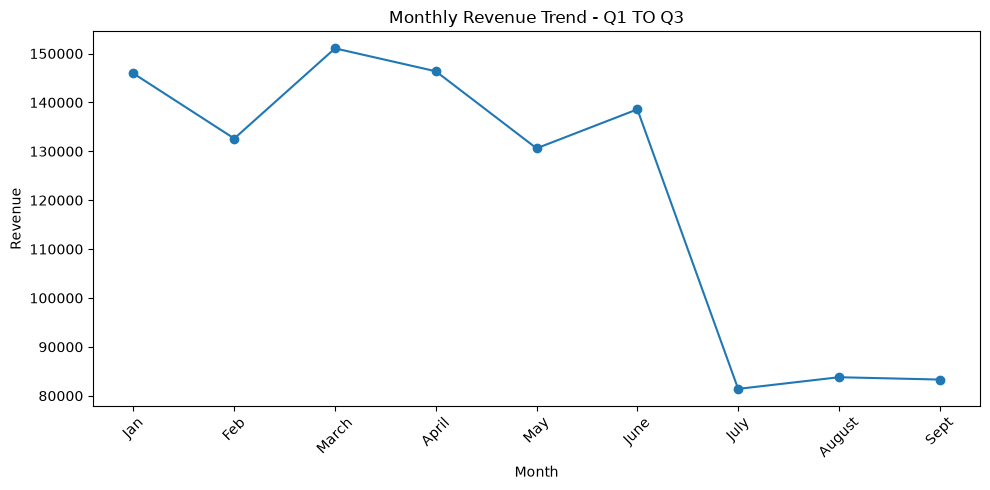

In [86]:
# visualise the change in revenue
plt.figure(figsize=(10,5))
plt.plot(monthly_revenue['month'], monthly_revenue['total_revenue'], marker='o')
plt.title("Monthly Revenue Trend - Q1 TO Q3")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

Insight:

Revenue remained relatively stable from January to June, despite some month-to-month fluctuations. A sharp decline occurred in July, with revenue falling by approximately 41.2% from June. Revenue then remained at a significantly lower level through August and September, indicating that the decline began in July and persisted throughout Q3.

### Revenue Waterfall

In [87]:
# create a table with channel and revenue change columns
waterfall_data = channel_revenue[['channel', 'revenue_change']].copy()
waterfall_data

,channel,revenue_change
0,paid_social,-30722.74
1,email,-24318.23
2,paid_search,-29687.25
3,direct,-26478.12
4,organic,-23595.86
5,referral,-25613.78
6,None,-6652.92


In [88]:
revenue

,quarter,order_count,total_revenue
0,Q2,2589,415576.07
1,Q3,2736,248507.17


In [89]:
# create labels and values for the waterfall chart
labels = [
    'Q2 Revenue',
    'Paid Social',
    'Email',
    'Paid Search',
    'Direct',
    'Organic',
    'Referral',
    'Unknown',
    'Q3 Revenue'
]

values = [
    415576.07,
    -30722.74,
    -24318.23,
    -29687.25,
    -26478.12,
    -23595.86,
    -25613.78,
    -6652.92,
    248507.17
]

In [90]:
# calculate cumulative positions
cumulative = [values[0]]

for value in values[1:-1]:
    cumulative.append(round(cumulative[-1] + value, 2))
    
cumulative.append(values[-1])

cumulative

[415576.07,
 384853.33,
 360535.1,
 330847.85,
 304369.73,
 280773.87,
 255160.09,
 248507.17,
 248507.17]

In [91]:
# calculate bar bottoms
bottom = [0] 
for i in range(1, len(values) - 1):
    bottom.append(cumulative[i])
bottom.append(0)

bottom

[0,
 384853.33,
 360535.1,
 330847.85,
 304369.73,
 280773.87,
 255160.09,
 248507.17,
 0]

In [92]:
# calculate the bar heights
height = [values[0]]
for value in values[1:-1]:
    height.append(abs(value))
height.append(values[-1])
height

[415576.07,
 30722.74,
 24318.23,
 29687.25,
 26478.12,
 23595.86,
 25613.78,
 6652.92,
 248507.17]

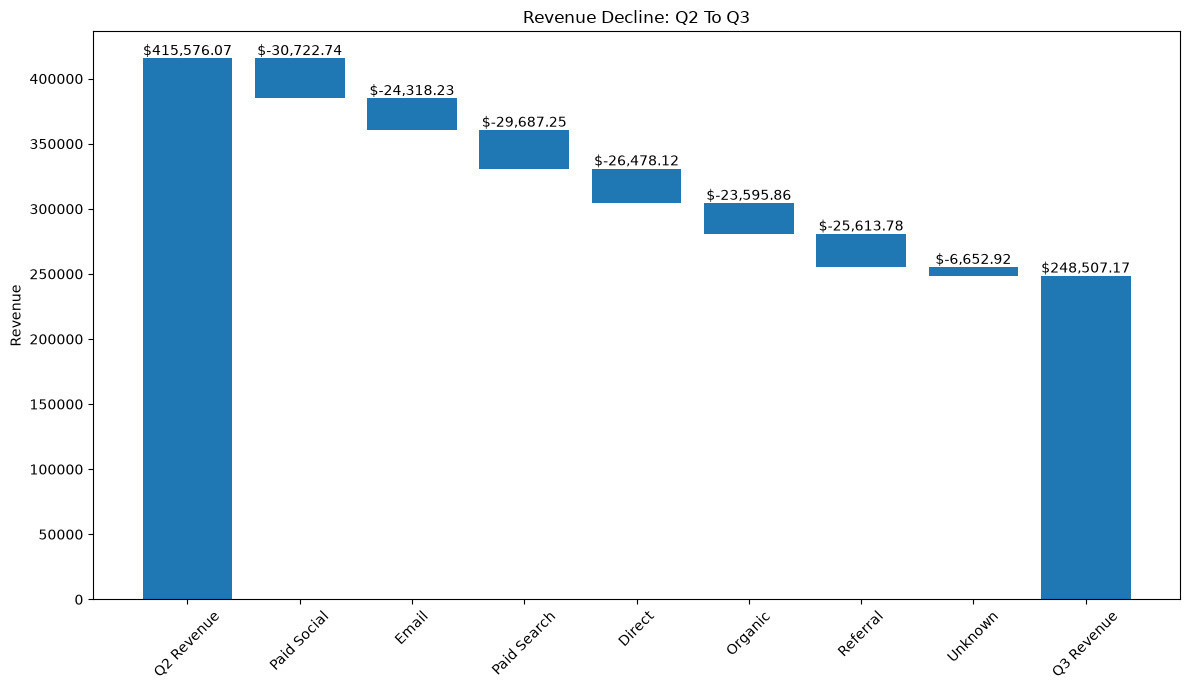

In [93]:
# create the plot
plt.figure(figsize=(12,7))
plt.bar(
    labels,
    height,
    bottom = bottom
)

# adding data labels
for i, value in enumerate(values):
    if i == 0 or i == len(values) - 1:
        label = f"${value:,.2f}"
        y = value
    else:
        label = f"${value:,.2f}"
        y = bottom[i] + height[i]

    plt.text(
        i,
        y,
        label,
        ha="center",
        va="bottom"
    )
    
plt.title("Revenue Decline: Q2 To Q3")
plt.xticks(rotation=45)
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

Insight:

Paid Social and Paid Search together account for about 60.4K of the 167.1K decline, making paid acquisition a particularly important contributor.
But because every channel declined, the evidence points toward a broader deterioration in revenue performance rather than a single-channel failure.

# 6. Recommendations

1. Investigate the broad-based revenue decline across all channels to identify the underlying factor affecting overall customer spending.

2. Review paid acquisition performance, particularly Paid Social and Paid Search, since they contributed the largest individual revenue declines.

3. Assess customer purchasing behaviour to understand why revenue is falling despite order volume remaining relatively strong.

4. Review discounts and refunds to determine whether changes in these areas are reducing net revenue.

5. Monitor channel performance in Q4 with weekly revenue, order volume, AOV, and refund-rate tracking to identify whether the decline is reversing.

# 7. Conclusion

NordCart experienced a significant 40.20% decline in revenue from Q2 to Q3, falling from 415,576.07  to 248,507.17. The decline occurred across all sales channels, with Paid Social and Paid Search contributing the largest individual revenue losses.

The analysis also shows that the decline was not simply caused by fewer orders, as order volume increased from 2,589 to 2,736. This indicates that the business needs to focus on understanding the factors affecting the value and profitability of those orders, particularly customer purchasing behaviour, discounts, and refunds.